# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [8]:
# TODO 1: one 1080p RGB frame, in MB
# 1920 * 1080 pixels * 3 channels * 1 byte/channel
frame_bytes = 1920 * 1080 * 3
frame_mb = frame_bytes / (1024 ** 2)

# TODO 2: frames per camera per day at 30 fps
# 30 frames/s * 60 s/min * 60 min/h * 24 h/day
frames_per_day = 30 * 60 * 60 * 24

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
# 400 cameras * (frames_per_day) * (frame_bytes) in Terabytes (1 TB = 1024^4 bytes)
total_bytes = 400 * frames_per_day * frame_bytes
fleet_tb = total_bytes / (1024 ** 4)

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
frame_bytes_small = 640 * 360 * 3
frames_per_day_small = 10 * 60 * 60 * 24
total_bytes_small = 400 * frames_per_day_small * frame_bytes_small
fleet_tb_small = total_bytes_small / (1024 ** 4)

pct_pixels_remaining = ((640 * 360) / (1920 * 1080)) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


```markdown
**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_
- **Spatial Evidence (Raster Interpolation / Spatial Resolution):** Downsampling to 360p reduces the number of pixels by nearly 89%. This leads to severe loss of high-frequency spatial details (e.g., license plate alphanumeric characters, fine facial features of suspects, or brand logos on clothing) because small details are blurred/smeared together by the interpolation process.
- **Temporal Evidence (Frame Rate / Correspondence Problem):** Dropping the frame rate from 30 fps to 10 fps increases the time step between consecutive frames from 33ms to 100ms. This can cause fast-moving objects (such as a thrown object, a rapid arm swing, or a fleeing vehicle) to suffer from severe motion blur or disappear entirely between frames. This introduces the *correspondence problem*, making it extremely difficult to track objects reliably or reconstruct the sequence of rapid movements during critical moments.
```

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

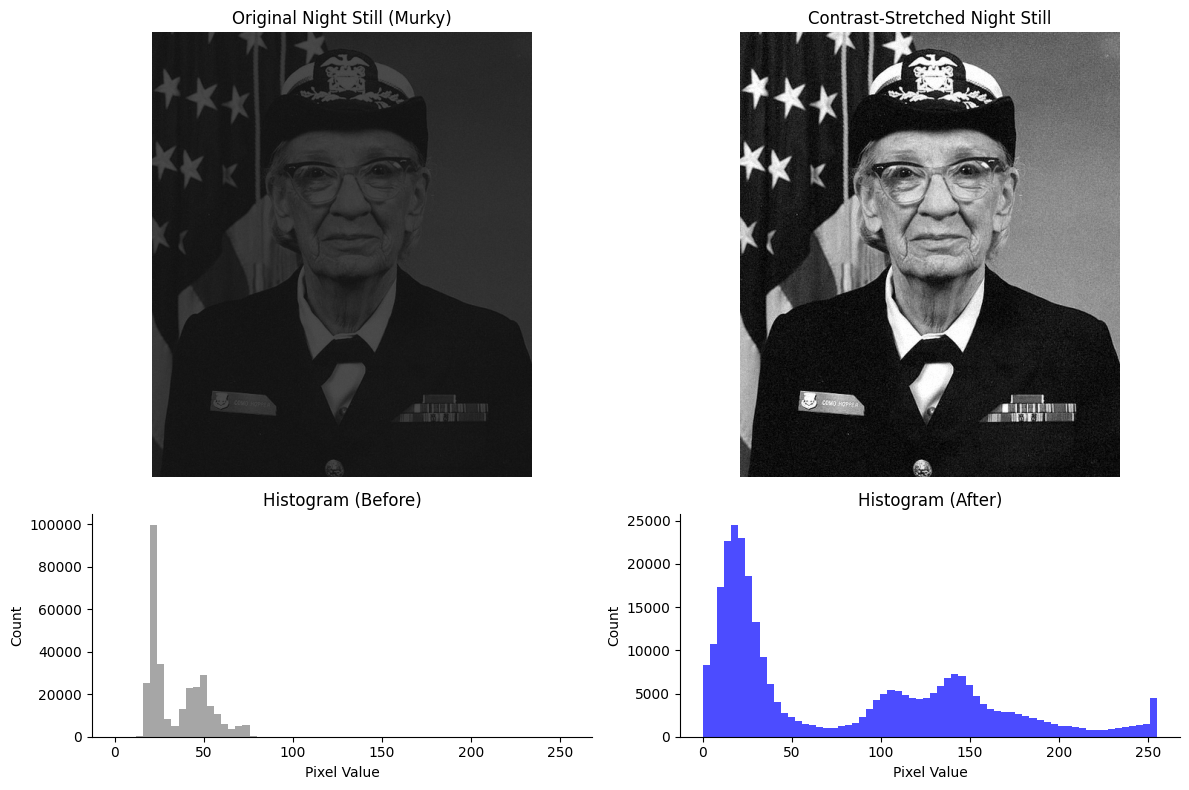

Contrast before: 0.609  ->  after: 1.000


In [9]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# Calculate percentiles robust to outliers (1st and 99th)
p1, p99 = np.percentile(night_still, [1, 99])

# TODO 2: robust Michelson contrast of night_still
c_before = michelson(p99, p1)

# TODO 3: contrast-stretched version of night_still
# Map p1 to 0, p99 to 255, and clip to 0-255
stretched = 255.0 * (night_still - p1) / (p99 - p1)
stretched = np.clip(stretched, 0, 255)

p1_after, p99_after = np.percentile(stretched, [1, 99])
c_after = michelson(p99_after, p1_after)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), gridspec_kw={"height_ratios": [2, 1]})

# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
# Before Stretching
axes[0, 0].imshow(night_still, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original Night Still (Murky)")
axes[0, 0].axis("off")

axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255), color="gray", alpha=0.7)
axes[1, 0].set_title("Histogram (Before)")
axes[1, 0].set_xlabel("Pixel Value")
axes[1, 0].set_ylabel("Count")

# After Stretching
axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Contrast-Stretched Night Still")
axes[0, 1].axis("off")

axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255), color="blue", alpha=0.7)
axes[1, 1].set_title("Histogram (After)")
axes[1, 1].set_xlabel("Pixel Value")
axes[1, 1].set_ylabel("Count")

plt.tight_layout()
plt.show()

print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

```markdown
**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_
- **Histogram Shape:** The original night image's histogram has a **narrow, low-contrast (or dark/unimodal)** shape. Nearly all pixels are packed tightly into a narrow range of low gray-level values on the left side of the scale, indicating very low luminance variance.
- **Why stretching makes it readable:** Contrast stretching maps the active, narrow interval of pixel values (from $p_1$ to $p_{99}$) linearly to the full $0-255$ dynamic range of the display. While it adds absolutely no new information (the underlying relative order and numeric entropy do not increase, and we simply scaled the existing values), it makes the image readable because it adapts the data to the human visual system's sensitivity, expanding the small intensity differences until they are wide enough for our eyes to distinguish.
- **Why a histogram alone cannot tell you *what* is in the picture:** A histogram is a global summary that completely discards all **spatial layout** and structural context of the pixels. It only counts *how many* pixels of each gray level exist, but says nothing about *where* they are. Two completely different images—such as a picture of a suspect and a random block of static noise with identical gray values—will yield the exact same histogram. This illustrates the concept "Same Histogram $\neq$ Same Image".
```

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing times:
  First: 68.70 s | Last: 78.10 s
Running times:
  First: 78.60 s | Last: 86.00 s


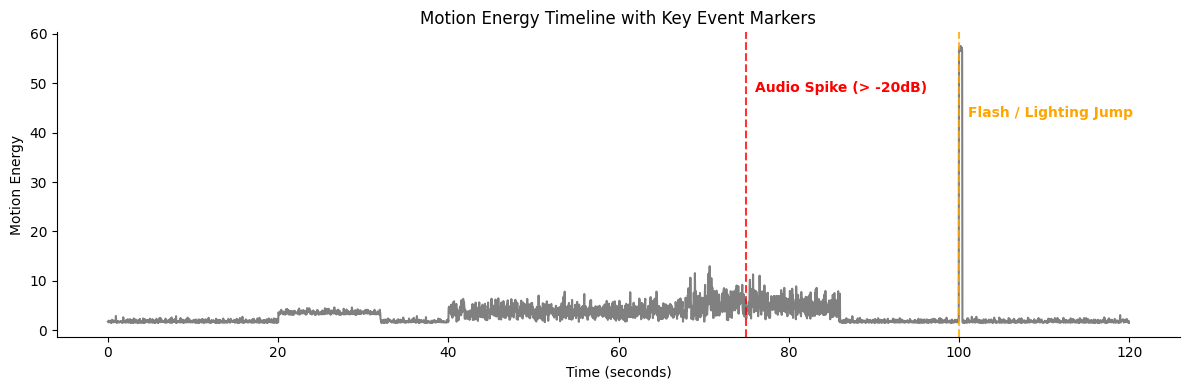

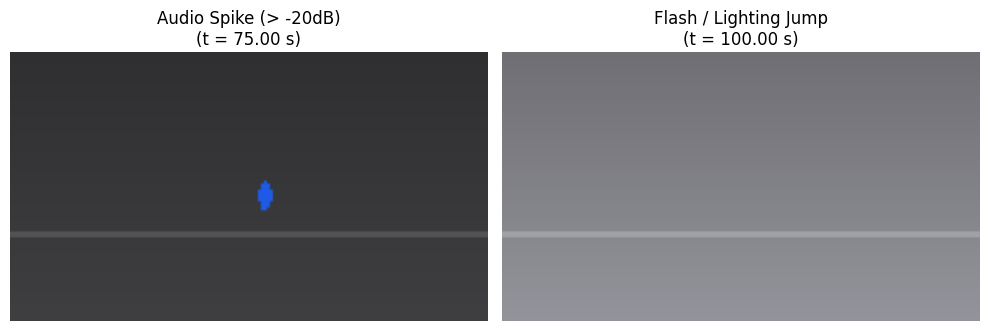

In [10]:
# 1-second window in frames is FPS (30 frames)
# Speed: distance traveled in pixels over 1 second.
dx = cctv["person_x"].diff(FPS)
dy = cctv["person_y"].diff(FPS)
speed = np.sqrt(dx**2 + dy**2) / (FPS * (1.0 / FPS)) # magnitude of motion vector per second (pixels/s)

# Find standing (< 3 px/s) and running (> 25 px/s) time ranges
standing_mask = speed < 3
running_mask = speed > 25

standing_times = cctv.loc[standing_mask, "time_s"]
running_times = cctv.loc[running_mask, "time_s"]

print("Standing times:")
if len(standing_times) > 0:
    print(f"  First: {standing_times.iloc[0]:.2f} s | Last: {standing_times.iloc[-1]:.2f} s")
else:
    print("  None detected")

print("Running times:")
if len(running_times) > 0:
    print(f"  First: {running_times.iloc[0]:.2f} s | Last: {running_times.iloc[-1]:.2f} s")
else:
    print("  None")

# Find event frame indices
# Audio event: audio_level_db first rises above -20 dB
audio_event_idx = cctv[cctv["audio_level_db"] > -20].index[0]
# Lighting event: mean_brightness jumps by more than 40 in one frame
lighting_event_idx = cctv[cctv["mean_brightness"].diff() > 40].index[0]

# Create a list of key events to plot
events = [
    ("Audio Spike (> -20dB)", audio_event_idx),
    ("Flash / Lighting Jump", lighting_event_idx)
]

# Plot timeline
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(cctv["time_s"], cctv["motion_energy"], color="gray", label="Motion Energy")

colors = ["red", "orange"]
for idx, (label, frame_idx) in enumerate(events):
    t_event = cctv.loc[frame_idx, "time_s"]
    ax.axvline(t_event, color=colors[idx], linestyle="--", alpha=0.8)
    ax.text(t_event + 1, ax.get_ylim()[1] * 0.8 - idx * 5, label, color=colors[idx], fontweight="bold")

ax.set_title("Motion Energy Timeline with Key Event Markers")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Motion Energy")
plt.tight_layout()
plt.show()

# Render keyframe for each event
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for i, (label, frame_idx) in enumerate(events):
    frame_data = cctv.iloc[frame_idx]
    frame_img = render_frame(frame_data)
    axes[i].imshow(frame_img)
    axes[i].set_title(f"{label}\n(t = {frame_data.time_s:.2f} s)")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

```markdown
**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_
- **Events Missed:** If we sampled keyframes uniformly every 20 seconds (e.g., at $t = 0, 20, 40, 60, 80, 100, 120$ s), we would likely miss both critical, transient events. The sudden glass breaking / audio spike at $t = 75$ s occurs in between the $60$ s and $80$ s sampling boundaries, and the brief 1-frame camera flash/lighting jump at $t = 100$ s could easily be skipped if the frame at exactly $100.0$ s does not capture the transient spike. These events are short-lived and sparse.
- **Lecture Concept:** The approach we used instead is **Content-Based Keyframe Selection** (or **Event-Driven / Content-Dependent Video Summarization** via temporal activity/motion-energy boundaries). This selectively extracts keyframes where localized feature gradients (such as motion energy spikes, audio level thresholds, or extreme lighting differences) segment the continuous stream into semantically meaningful events.
```

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

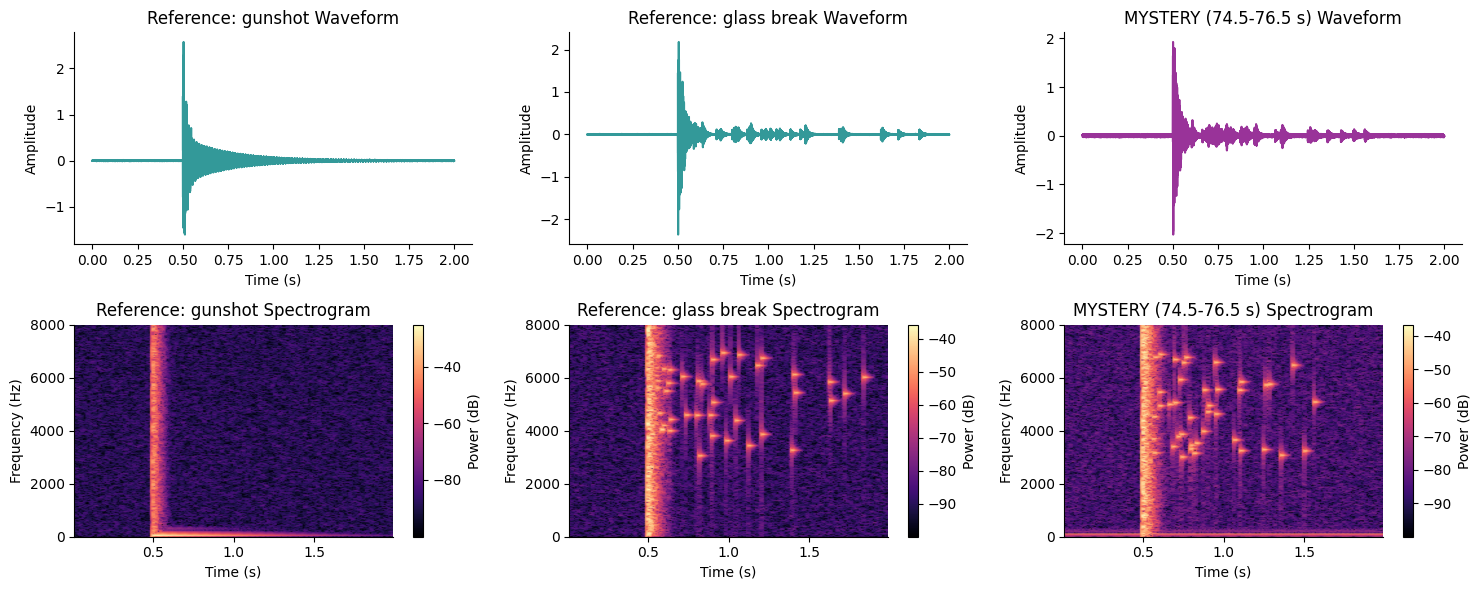

High-frequency energy fractions (>3 kHz, 0.2 - 1.2s post-impact):
  Reference: gunshot: 0.30%
  Reference: glass break: 98.92%
  MYSTERY (74.5-76.5 s): 87.35%

VERDICT: The mystery sound is a GLASS BREAK.


In [11]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {
    "Reference: gunshot": ref_gunshot[1],
    "Reference: glass break": ref_glass[1],
    "MYSTERY (74.5-76.5 s)": mystery
}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
hf_fraction = {}

for col_idx, (name, signal_data) in enumerate(clips.items()):
    t_clip = np.arange(len(signal_data)) / FS

    # Plot waveform
    axes[0, col_idx].plot(t_clip, signal_data, color="purple" if "MYSTERY" in name else "teal", alpha=0.8)
    axes[0, col_idx].set_title(f"{name} Waveform")
    axes[0, col_idx].set_xlabel("Time (s)")
    axes[0, col_idx].set_ylabel("Amplitude")

    # Plot spectrogram
    f, t_spec, Sxx = signal.spectrogram(signal_data, fs=FS, nperseg=512, noverlap=384)
    Sxx_db = 10 * np.log10(Sxx + 1e-10)

    mesh = axes[1, col_idx].pcolormesh(t_spec, f, Sxx_db, shading="gouraud", cmap="magma")
    axes[1, col_idx].set_title(f"{name} Spectrogram")
    axes[1, col_idx].set_xlabel("Time (s)")
    axes[1, col_idx].set_ylabel("Frequency (Hz)")
    axes[1, col_idx].set_ylim(0, 8000)
    fig.colorbar(mesh, ax=axes[1, col_idx], label="Power (dB)")

    # TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
    # 0.2 to 1.2 s after 0.5 s impact means time range: [0.7, 1.7] s
    time_mask = (t_spec >= 0.7) & (t_spec <= 1.7)
    freq_mask_high = f > 3000

    total_energy = Sxx[:, time_mask].sum()
    high_energy = Sxx[freq_mask_high, :][:, time_mask].sum()

    hf_fraction[name] = high_energy / total_energy if total_energy > 0 else 0.0

plt.tight_layout()
plt.show()

print("High-frequency energy fractions (>3 kHz, 0.2 - 1.2s post-impact):")
for name, frac in hf_fraction.items():
    print(f"  {name}: {frac:.2%}")

# TODO 4: verdict
verdict = "GLASS BREAK" if hf_fraction["MYSTERY (74.5-76.5 s)"] > 0.15 else "GUNSHOT"
print(f"\nVERDICT: The mystery sound is a {verdict}.")

```markdown
**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_
- **Waveform Analysis:** No, we could not have confidently distinguished the gunshot from the glass break using only the waveforms. All three waveforms look almost identical in the time domain: a sudden, sharp, high-amplitude spike at the 0.5-second impact mark followed by a rapid decay back to near-silent ambient noise.
- **What the Spectrogram Adds (3 Dimensions):** The spectrogram adds invaluable frequency-domain details over time. The three coordinates/dimensions it displays are:
  1. **Time** (represented on the horizontal x-axis).
  2. **Frequency** (represented on the vertical y-axis).
  3. **Magnitude/Power** (represented by color intensity or luminance, typically measured in dB).
- **Deciding Visual Pattern:** The visual pattern of **scattered high-frequency specks** (the lingering, persistent energy blocks concentrated at 3–7 kHz continuing long after the initial vertical strike of the impact) conclusively decided the verdict as a **glass break**. A gunshot, in contrast, shows only a sharp, broadband **vertical stripe** indicating a sudden explosion across all frequencies with no lingering high-frequency energy.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

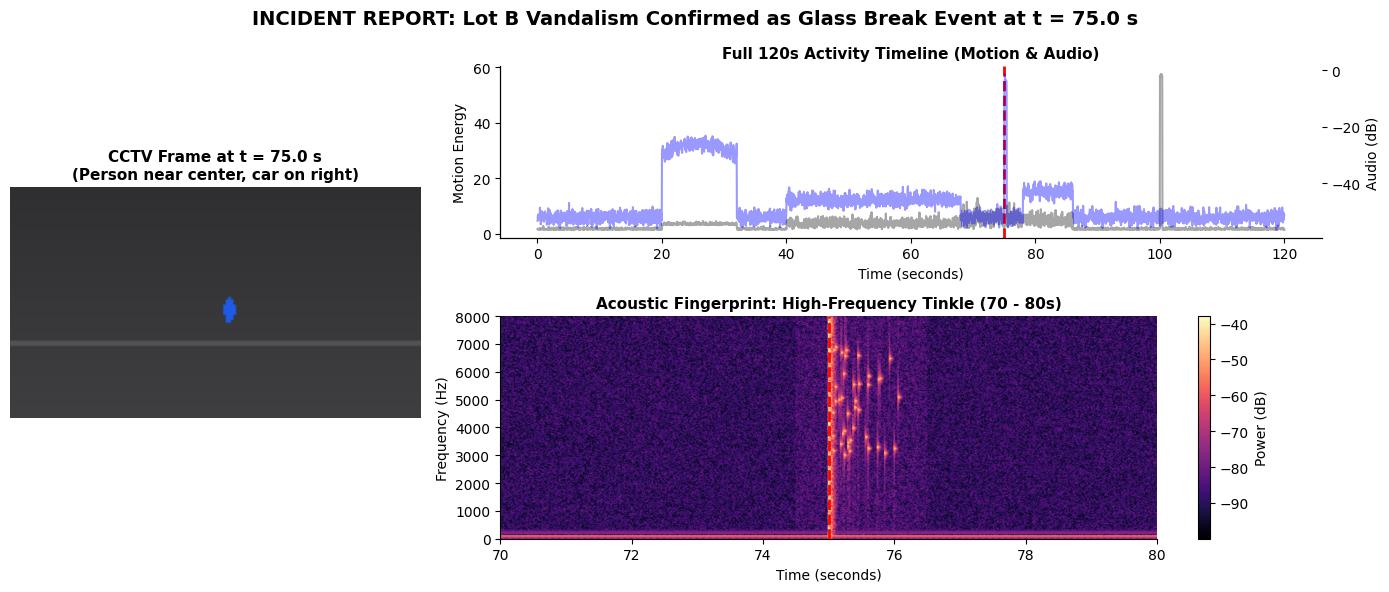

In [12]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])

# 1. Left Panel: Rendered frame at t = 75s (frame index = 75 * 30 = 2250)
ax_frame = fig.add_subplot(gs[:, 0])
idx_75 = int(t_sel * FPS)
frame_data_75 = cctv.iloc[idx_75]
frame_img_75 = render_frame(frame_data_75)
ax_frame.imshow(frame_img_75)
ax_frame.set_title(f"CCTV Frame at t = {t_sel:.1f} s\n(Person near center, car on right)", fontsize=11, fontweight="bold")
ax_frame.axis("off")

# 2. Top Right Panel: Timeline (0 - 120s)
ax_time = fig.add_subplot(gs[0, 1])
ax_time.plot(cctv["time_s"], cctv["motion_energy"], color="gray", label="Motion Energy", alpha=0.7)
ax_time_twin = ax_time.twinx()
ax_time_twin.plot(cctv["time_s"], cctv["audio_level_db"], color="blue", label="Audio (dB)", alpha=0.4)
ax_time.axvline(t_sel, color="red", linestyle="--", linewidth=2, label="Incident Marker")
ax_time.set_title("Full 120s Activity Timeline (Motion & Audio)", fontsize=11, fontweight="bold")
ax_time.set_xlabel("Time (seconds)")
ax_time.set_ylabel("Motion Energy")
ax_time_twin.set_ylabel("Audio (dB)")

# 3. Bottom Right Panel: Spectrogram (70 - 80s)
ax_spec = fig.add_subplot(gs[1, 1])
f_full, t_full, Sxx_full = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
Sxx_full_db = 10 * np.log10(Sxx_full + 1e-10)

# Shift spectrogram time coordinates to match the absolute timeline (starts at 70s)
t_full_absolute = 70.0 + t_full
mesh_full = ax_spec.pcolormesh(t_full_absolute, f_full, Sxx_full_db, shading="gouraud", cmap="magma")
ax_spec.axvline(t_sel, color="red", linestyle="--", linewidth=2)
ax_spec.set_xlim(70, 80)
ax_spec.set_ylim(0, 8000)
ax_spec.set_title("Acoustic Fingerprint: High-Frequency Tinkle (70 - 80s)", fontsize=11, fontweight="bold")
ax_spec.set_xlabel("Time (seconds)")
ax_spec.set_ylabel("Frequency (Hz)")
fig.colorbar(mesh_full, ax=ax_spec, label="Power (dB)")

# 4. Conclusion Title
fig.suptitle("INCIDENT REPORT: Lot B Vandalism Confirmed as Glass Break Event at t = 75.0 s", fontsize=14, fontweight="bold", y=0.98)

plt.tight_layout()
plt.show()

```markdown
**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_
- **What would go wrong:** An audio offset of +2 seconds would break the temporal alignment between the visual cues and acoustic evidence. This mismatch would severely compromise the integrity of the investigation during the briefing: the suspect would appear to run away ($t = 78.6$ s) *before* the sound of the glass breaking actually occurs on the audio track ($t = 75 + 2 = 77$ s). This temporal paradox violates causal consistency, leading to confusion, invalidating your timeline, and potentially creating reasonable doubt about the security team's evidence alignment.
- **Which panel would make the mistake visible:** The **Top Right Panel (Full 120s Activity Timeline)** would immediately expose this error. It plots both `motion_energy` (extracted from the video) and `audio_level_db` (extracted from the audio) side by side on a shared horizontal x-axis (time). If the audio track were delayed by 2 seconds, the massive audio spike would shift to $t = 77$ s, while the red incident line would remain statically anchored to the video frame's action at $t = 75$ s, showing a glaring 2-second gap between the physical motion impact and the sound level peak.
```

```markdown
**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_
- **Incident Summary:** At $t = 75.0$ s, a suspect stood stationary in Lot B ($68.70\text{ s} - 78.10\text{ s}$), broke a vehicle window (confirmed as a glass break via acoustic analysis), and immediately fled the scene running ($78.60\text{ s} - 86.00\text{ s}$).
- **Visualization Recommendation:** I highly recommend putting our **Synchronized Multimodal View** first in your briefing. By integrating video spatial structure, timeline-level changes, and sound frequencies across time and magnitude, this unified panel guides the viewer through the logical flow of *structure \rightarrow pattern \rightarrow change \rightarrow event \rightarrow meaning* on a single screen.
- **Storage Policy & Crucial Evidence:** To manage our 400-camera fleet, we should adopt the downsampled **360p at 10 fps** storage standard to slash our daily demand from a staggering 5,866.0 TB to a manageable 217.3 TB. However, this policy must **never** sacrifice our audio raw resolution (16 kHz sampling rate), because downsampling high-frequency acoustic data would obliterate the spectral tinkle pattern above 3 kHz that is absolutely essential to legally differentiate a glass break from a gunshot.
```